# ALS 5.3.1 Shadow4 Digital twin for blop
khchan@lbl.gov, awojdyla@lbl.gov, August 2026

/opt/anaconda3/lib/python3.13/site-packages/srxraylib/plot/gol.py:786: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  axScatter.set_xlim( xrange )


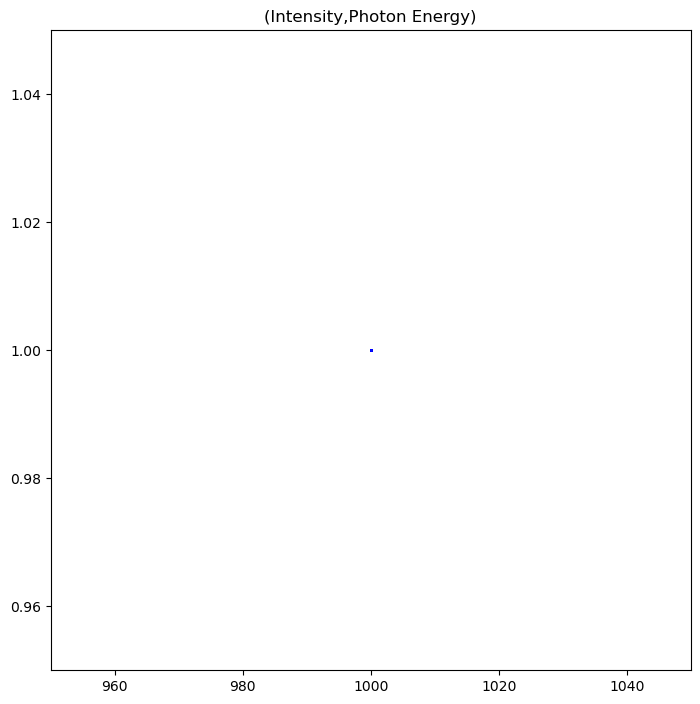

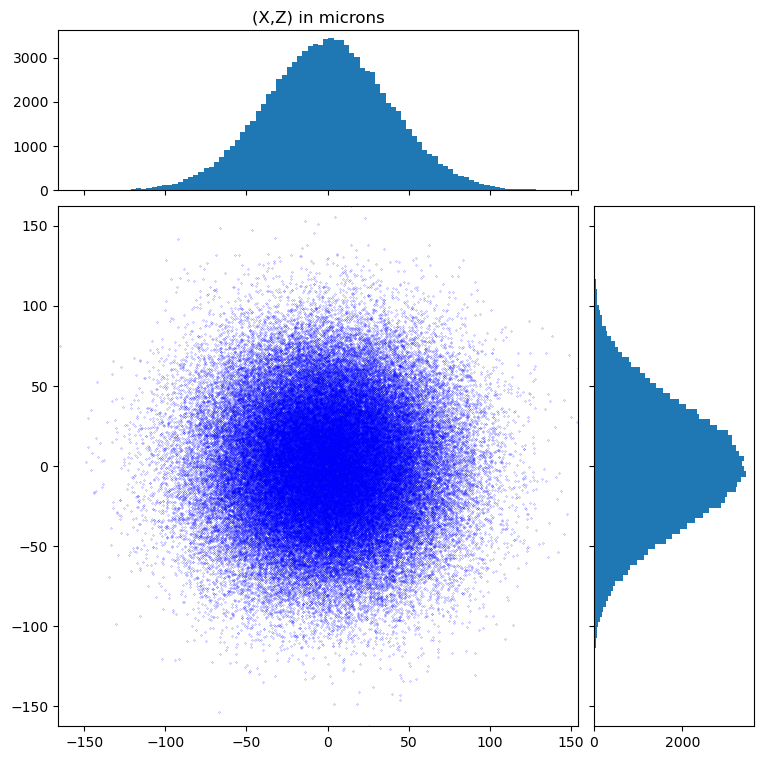

In [2]:
import numpy as np
from dabax.dabax_xraylib import DabaxXraylib
from shadow4.beamline.s4_beamline import S4Beamline

beamline = S4Beamline()

#
#
#
from shadow4.sources.source_geometrical.source_geometrical import SourceGeometrical
light_source = SourceGeometrical(name='Geometrical Source', nrays=100000, seed=0)
light_source.set_spatial_type_gaussian(sigma_h=0,sigma_v=0)
light_source.set_depth_distribution_off()
light_source.set_angular_distribution_gaussian(sigdix=1.9e-05,sigdiz=1.9e-05)
light_source.set_energy_distribution_singleline(1000, unit='eV')
light_source.set_polarization(polarization_degree=1, phase_diff=0, coherent_beam=1)
beam = light_source.get_beam()

beamline.set_light_source(light_source)

# optical element number XX
boundary_shape = None
        
from shadow4.beamline.optical_elements.mirrors.s4_toroid_mirror import S4ToroidMirror
optical_element = S4ToroidMirror(name='Generic Mirror', boundary_shape=boundary_shape,
    surface_calculation=1, # 0=Internal calculation, 1=External 
    min_radius=0.06,  # min_radius = sagittal
    maj_radius=2400,  # maj_radius = tangential
    f_torus=0,
    p_focus=12, q_focus=12, grazing_angle=0.005, # for surface_calculation=0
    f_reflec=0, # reflectivity of surface: 0=no reflectivity, 1=full polarization
    f_refl=0, # for f_reflec=1: file: 0=prerefl, 2=(mrad, refl), 3=(eV, refl), 4=(eV, mrad, refl); 1=refr index, 5=xraylib, 6=dabax
    file_refl='<none>', # for f_refl=0,2,3,4
    refraction_index=0.99999+0.001j, # for f_refl=1
    coating_material='Si', coating_density=2.33, # for f_refl=5,6
    coating_roughness=0, # for f_refl=0,1,5,6
    dabax=None, # if using dabax (f_reflec=1,f_refl=6), instance of DabaxXraylib() (use None for default)
    )

from syned.beamline.element_coordinates import ElementCoordinates
coordinates = ElementCoordinates(p=12, q=1, angle_radial=1.565796327, angle_azimuthal=0, angle_radial_out=1.565796327)
movements = None
from shadow4.beamline.optical_elements.mirrors.s4_toroid_mirror import S4ToroidMirrorElement
beamline_element = S4ToroidMirrorElement(optical_element=optical_element, coordinates=coordinates, movements=movements, input_beam=beam)

beam, footprint = beamline_element.trace_beam()

beamline.append_beamline_element(beamline_element)

# optical element number XX
boundary_shape = None

from shadow4.beamline.optical_elements.absorbers.s4_screen import S4Screen
optical_element = S4Screen(name='screen at focus', boundary_shape=boundary_shape,
    i_abs=0, # attenuation: 0=No, 1=prerefl file, 2=xraylib, 3=dabax
    i_stop=0, # 0=slit or aperture, 1=beam stop
    thick=0, # for i_abs>0
    file_abs='<specify file name>', # for i_abs=1
    material='Au', density=19.3, # for i_abs=2,3
    dabax=None, # if using dabax (i_abs=3), instance of DabaxXraylib() (use None for default)
    )

from syned.beamline.element_coordinates import ElementCoordinates
coordinates = ElementCoordinates(p=11, q=0, angle_radial=0, angle_azimuthal=0, angle_radial_out=3.141592654)
from shadow4.beamline.optical_elements.absorbers.s4_screen import S4ScreenElement
beamline_element = S4ScreenElement(optical_element=optical_element, coordinates=coordinates, input_beam=beam)

beam, footprint = beamline_element.trace_beam()

beamline.append_beamline_element(beamline_element)

# optical element number XX
boundary_shape = None

from shadow4.beamline.optical_elements.absorbers.s4_screen import S4Screen
optical_element = S4Screen(name='screen 2m after focus', boundary_shape=boundary_shape,
    i_abs=0, # attenuation: 0=No, 1=prerefl file, 2=xraylib, 3=dabax
    i_stop=0, # 0=slit or aperture, 1=beam stop
    thick=0, # for i_abs>0
    file_abs='<specify file name>', # for i_abs=1
    material='Au', density=19.3, # for i_abs=2,3
    dabax=None, # if using dabax (i_abs=3), instance of DabaxXraylib() (use None for default)
    )

from syned.beamline.element_coordinates import ElementCoordinates
coordinates = ElementCoordinates(p=2, q=0, angle_radial=0, angle_azimuthal=0, angle_radial_out=3.141592654)
from shadow4.beamline.optical_elements.absorbers.s4_screen import S4ScreenElement
beamline_element = S4ScreenElement(optical_element=optical_element, coordinates=coordinates, input_beam=beam)

beam, footprint = beamline_element.trace_beam()

beamline.append_beamline_element(beamline_element)


# test plot
if True:
   from srxraylib.plot.gol import plot_scatter
   plot_scatter(beam.get_photon_energy_eV(nolost=1), beam.get_column(23, nolost=1), title='(Intensity,Photon Energy)', plot_histograms=0)
   plot_scatter(1e6 * beam.get_column(1, nolost=1), 1e6 * beam.get_column(3, nolost=1), title='(X,Z) in microns')

In [3]:
import numpy as np
from dabax.dabax_xraylib import DabaxXraylib
from shadow4.beamline.s4_beamline import S4Beamline

def run_als531(Rtan_m=2400,drift_m=2):
    beamline = S4Beamline()

    #
    #
    #
    from shadow4.sources.source_geometrical.source_geometrical import SourceGeometrical
    light_source = SourceGeometrical(name='Geometrical Source', nrays=100000, seed=0)
    light_source.set_spatial_type_gaussian(sigma_h=0,sigma_v=0)
    light_source.set_depth_distribution_off()
    light_source.set_angular_distribution_gaussian(sigdix=1.9e-05,sigdiz=1.9e-05)
    light_source.set_energy_distribution_singleline(1000, unit='eV')
    light_source.set_polarization(polarization_degree=1, phase_diff=0, coherent_beam=1)
    beam = light_source.get_beam()

    beamline.set_light_source(light_source)

    # optical element number XX
    boundary_shape = None
            
    from shadow4.beamline.optical_elements.mirrors.s4_toroid_mirror import S4ToroidMirror
    optical_element = S4ToroidMirror(name='Generic Mirror', boundary_shape=boundary_shape,
        surface_calculation=1, # 0=Internal calculation, 1=External 
        min_radius=0.06,  # min_radius = sagittal
        maj_radius=Rtan_m,  # maj_radius = tangential
        f_torus=0,
        p_focus=12, q_focus=12, grazing_angle=0.005, # for surface_calculation=0
        f_reflec=0, # reflectivity of surface: 0=no reflectivity, 1=full polarization
        f_refl=0, # for f_reflec=1: file: 0=prerefl, 2=(mrad, refl), 3=(eV, refl), 4=(eV, mrad, refl); 1=refr index, 5=xraylib, 6=dabax
        file_refl='<none>', # for f_refl=0,2,3,4
        refraction_index=0.99999+0.001j, # for f_refl=1
        coating_material='Si', coating_density=2.33, # for f_refl=5,6
        coating_roughness=0, # for f_refl=0,1,5,6
        dabax=None, # if using dabax (f_reflec=1,f_refl=6), instance of DabaxXraylib() (use None for default)
        )

    from syned.beamline.element_coordinates import ElementCoordinates
    coordinates = ElementCoordinates(p=12, q=1, angle_radial=1.565796327, angle_azimuthal=0, angle_radial_out=1.565796327)
    movements = None
    from shadow4.beamline.optical_elements.mirrors.s4_toroid_mirror import S4ToroidMirrorElement
    beamline_element = S4ToroidMirrorElement(optical_element=optical_element, coordinates=coordinates, movements=movements, input_beam=beam)

    beam, footprint = beamline_element.trace_beam()

    beamline.append_beamline_element(beamline_element)

    # optical element number XX
    boundary_shape = None

    from shadow4.beamline.optical_elements.absorbers.s4_screen import S4Screen
    optical_element = S4Screen(name='screen at focus', boundary_shape=boundary_shape,
        i_abs=0, # attenuation: 0=No, 1=prerefl file, 2=xraylib, 3=dabax
        i_stop=0, # 0=slit or aperture, 1=beam stop
        thick=0, # for i_abs>0
        file_abs='<specify file name>', # for i_abs=1
        material='Au', density=19.3, # for i_abs=2,3
        dabax=None, # if using dabax (i_abs=3), instance of DabaxXraylib() (use None for default)
        )

    from syned.beamline.element_coordinates import ElementCoordinates
    coordinates = ElementCoordinates(p=11, q=0, angle_radial=0, angle_azimuthal=0, angle_radial_out=3.141592654)
    from shadow4.beamline.optical_elements.absorbers.s4_screen import S4ScreenElement
    beamline_element = S4ScreenElement(optical_element=optical_element, coordinates=coordinates, input_beam=beam)

    beam, footprint = beamline_element.trace_beam()

    beamline.append_beamline_element(beamline_element)

    # optical element number XX
    boundary_shape = None

    from shadow4.beamline.optical_elements.absorbers.s4_screen import S4Screen
    optical_element = S4Screen(name='screen 2m after focus', boundary_shape=boundary_shape,
        i_abs=0, # attenuation: 0=No, 1=prerefl file, 2=xraylib, 3=dabax
        i_stop=0, # 0=slit or aperture, 1=beam stop
        thick=0, # for i_abs>0
        file_abs='<specify file name>', # for i_abs=1
        material='Au', density=19.3, # for i_abs=2,3
        dabax=None, # if using dabax (i_abs=3), instance of DabaxXraylib() (use None for default)
        )

    from syned.beamline.element_coordinates import ElementCoordinates
    coordinates = ElementCoordinates(p=drift_m, q=0, angle_radial=0, angle_azimuthal=0, angle_radial_out=3.141592654)
    from shadow4.beamline.optical_elements.absorbers.s4_screen import S4ScreenElement
    beamline_element = S4ScreenElement(optical_element=optical_element, coordinates=coordinates, input_beam=beam)

    beam, footprint = beamline_element.trace_beam()

    beamline.append_beamline_element(beamline_element)
    return beam

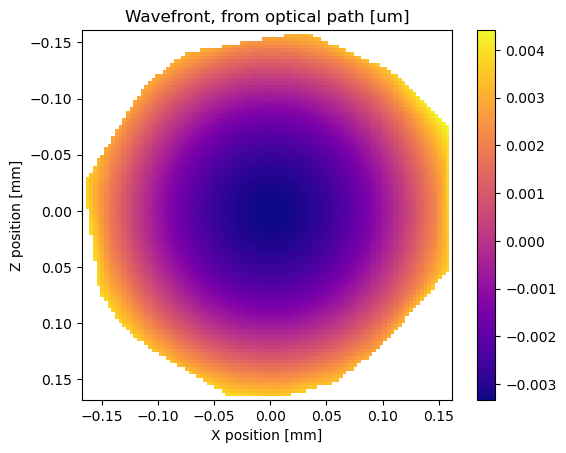

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.interpolate as interpolate

beam = run_als531(Rtan_m=2400,drift_m=2)

Nx=101 
Nz=101

# get the rays and their optical path
x1 = beam.get_column(1)
z1 = beam.get_column(3)
path1 = beam.get_column(13)

# resampling the OPD on a constant grid
x_lin = np.linspace(np.min(x1), np.max(x1), Nx)
z_lin = np.linspace(np.min(z1), np.max(z1), Nx)
X, Z = np.meshgrid(x_lin,z_lin)
wfe1 = interpolate.griddata((x1,z1),path1,(X,Z),method='linear')

#removal pf piston
wfe_um = (wfe1-np.nanmean(wfe1))*1e6

# scale factor for plotting display
scalefactor = 1E3
plt.imshow(wfe_um,extent=(X[0,0]*scalefactor,X[0,-1]*scalefactor,Z[-1,0]*scalefactor,Z[0,0]*scalefactor))
plt.title("Wavefront, from optical path [um]")
plt.xlabel("X position [mm]")
plt.ylabel("Z position [mm]")
plt.colorbar()
plt.set_cmap('plasma')
plt.show()

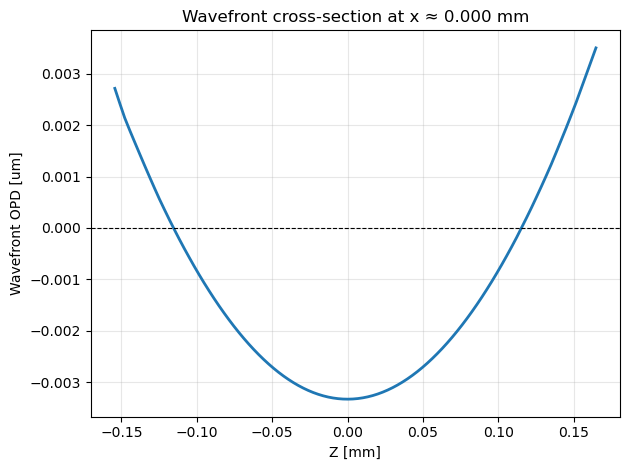

In [10]:
# cross section through the wavefront around x = 0
x_idx = np.argmin(np.abs(X[0, :]))
x0 = X[0, x_idx]
z_cross = Z[:, x_idx]
wfe_cross = wfe_um[:, x_idx]

valid = ~np.isnan(wfe_cross)
z_cross = z_cross[valid]
wfe_cross = wfe_cross[valid]

plt.figure()
plt.plot(z_cross * 1e3, wfe_cross, color='tab:blue', lw=2)
plt.axhline(0, color='black', lw=0.8, ls='--')
plt.title(f"Wavefront cross-section at x ≈ {x0 * 1e3:.3f} mm")
plt.xlabel("Z [mm]")
plt.ylabel("Wavefront OPD [um]")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Quadratic fit coefficients (meters): a=2.513695e+05, b=-7.793125e-03, c=-3.336977e-03


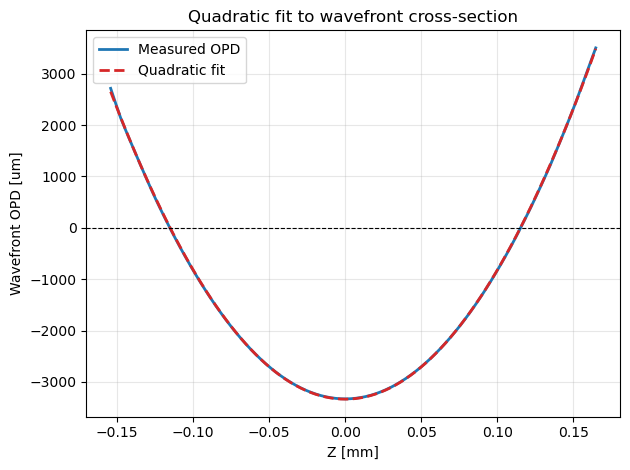

In [11]:
# Quadratic fit to the wavefront cross-section
# z_cross and wfe_cross are already defined in the notebook and filtered to valid points

coeffs = np.polyfit(z_cross, wfe_cross, 2)
p2 = np.poly1d(coeffs)
wfe_fit = p2(z_cross)

print(f"Quadratic fit coefficients (meters): a={coeffs[0]:.6e}, b={coeffs[1]:.6e}, c={coeffs[2]:.6e}")

plt.figure()
plt.plot(z_cross * 1e3, wfe_cross * 1e6, color='tab:blue', lw=2, label='Measured OPD')
plt.plot(z_cross * 1e3, wfe_fit * 1e6, color='tab:red', lw=2, ls='--', label='Quadratic fit')
plt.axhline(0, color='black', lw=0.8, ls='--')
plt.title("Quadratic fit to wavefront cross-section")
plt.xlabel("Z [mm]")
plt.ylabel("Wavefront OPD [um]")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [12]:
# Distance to the nearest focus from the quadratic wavefront fit
# OPD(z) ~= a*z^2 + b*z + c, with z in meters and OPD in meters
a = coeffs[0]*1e-6

# For a spherical wavefront, OPD(z) = (z - z0)^2 / (2*R) near the focus.
# Therefore the radius of curvature is:
R = 1.0 / (2.0 * abs(a))  # meters

# Optional cross-check using the wavelength:
wavelength_m = 1.24e-9  # 1 keV wavelength in meters
phase_coeff = (2.0 * np.pi / wavelength_m) * a
R_check = np.pi / (wavelength_m * abs(phase_coeff))

print(f"Quadratic OPD coefficient a = {a:.6e} 1/m")
print(f"Radius of curvature R = {R:.6e} m = {R*1e6:.3f} um")
print(f"Distance to nearest focus ~= {R:.6e} m = {R*1e6:.3f} um")
print(f"Check from phase coefficient: {R_check:.6e} m")

Quadratic OPD coefficient a = 2.513695e-01 1/m
Radius of curvature R = 1.989104e+00 m = 1989103.690 um
Distance to nearest focus ~= 1.989104e+00 m = 1989103.690 um
Check from phase coefficient: 1.989104e+00 m


## remove piston, tilt and power

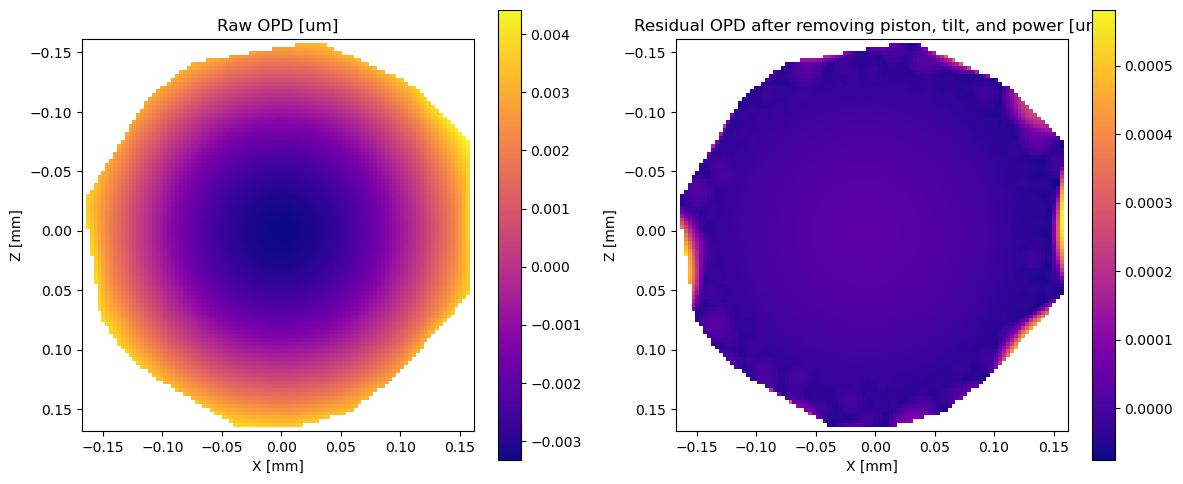

2D fit coefficients (um): piston=-3.360937e-03, tilt_x=6.195849e-02, tilt_z=-8.673155e-03, power=2.538814e+05
Residual RMS (um): 5.526932e-05


In [13]:
# 2D polynomial fit to remove piston, tilt, and power from the wavefront
# Uses the existing X, Z and wfe_um arrays from the previous cells

Xv = X.ravel()
Zv = Z.ravel()
Wv = wfe_um.ravel()

valid = np.isfinite(Wv)
Xv = Xv[valid]
Zv = Zv[valid]
Wv = Wv[valid]

# Model: piston + x-tilt + z-tilt + power (x^2 + z^2)
A = np.column_stack([
    np.ones_like(Xv),
    Xv,
    Zv,
    Xv**2 + Zv**2,
])

coef, *_ = np.linalg.lstsq(A, Wv, rcond=None)
a0, ax, az, apow = coef

fit_2d = a0 + ax * X + az * Z + apow * (X**2 + Z**2)
wfe_residual = wfe_um - fit_2d

# Optional: remove mean residual so the display is centered
wfe_residual_centered = wfe_residual - np.nanmean(wfe_residual)

# Display raw and fitted residuals
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

im1 = ax1.imshow(
    wfe_um,
    extent=(X[0, 0] * 1e3, X[0, -1] * 1e3, Z[-1, 0] * 1e3, Z[0, 0] * 1e3),
    cmap="plasma",
    origin="upper",
)
ax1.set_title("Raw OPD [um]")
ax1.set_xlabel("X [mm]")
ax1.set_ylabel("Z [mm]")
fig.colorbar(im1, ax=ax1)

im2 = ax2.imshow(
    wfe_residual_centered,
    extent=(X[0, 0] * 1e3, X[0, -1] * 1e3, Z[-1, 0] * 1e3, Z[0, 0] * 1e3),
    cmap="plasma",
    origin="upper",
)
ax2.set_title("Residual OPD after removing piston, tilt, and power [um]")
ax2.set_xlabel("X [mm]")
ax2.set_ylabel("Z [mm]")
fig.colorbar(im2, ax=ax2)

plt.tight_layout()
plt.show()

# Print coefficients
print(f"2D fit coefficients (um): piston={a0:.6e}, tilt_x={ax:.6e}, tilt_z={az:.6e}, power={apow:.6e}")
print(f"Residual RMS (um): {np.nanstd(wfe_residual_centered):.6e}")

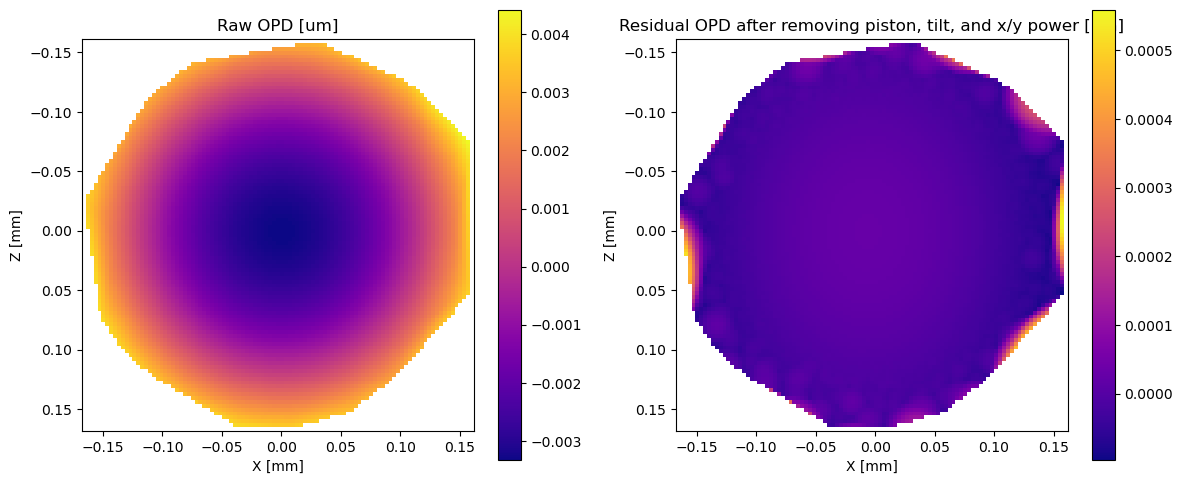

2D fit coefficients (um): piston=-3.360386e-03, tilt_x=6.156552e-02, tilt_z=-2.556151e-04, power_x=2.547806e+05, power_z=2.528567e+05
Residual RMS (um): 5.427532e-05


In [14]:
# Separate power terms in x and y (x^2 and z^2 independently)
# Use the existing X, Z, and wfe_um arrays from the notebook

Xv = X.ravel()
Zv = Z.ravel()
Wv = wfe_um.ravel()

valid = np.isfinite(Wv)
Xv = Xv[valid]
Zv = Zv[valid]
Wv = Wv[valid]

# Model: piston + x-tilt + z-tilt + x^2 power + z^2 power
A = np.column_stack([
    np.ones_like(Xv),
    Xv,
    Zv,
    Xv**2,
    Zv**2,
])

coef, *_ = np.linalg.lstsq(A, Wv, rcond=None)
a0, ax, az, apow_x, apow_z = coef

fit_2d = a0 + ax * X + az * Z + apow_x * X**2 + apow_z * Z**2
wfe_residual = wfe_um - fit_2d
wfe_residual_centered = wfe_residual - np.nanmean(wfe_residual)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

im1 = ax1.imshow(
    wfe_um,
    extent=(X[0, 0] * 1e3, X[0, -1] * 1e3, Z[-1, 0] * 1e3, Z[0, 0] * 1e3),
    cmap="plasma",
    origin="upper",
)
ax1.set_title("Raw OPD [um]")
ax1.set_xlabel("X [mm]")
ax1.set_ylabel("Z [mm]")
fig.colorbar(im1, ax=ax1)

im2 = ax2.imshow(
    wfe_residual_centered,
    extent=(X[0, 0] * 1e3, X[0, -1] * 1e3, Z[-1, 0] * 1e3, Z[0, 0] * 1e3),
    cmap="plasma",
    origin="upper",
)
ax2.set_title("Residual OPD after removing piston, tilt, and x/y power [um]")
ax2.set_xlabel("X [mm]")
ax2.set_ylabel("Z [mm]")
fig.colorbar(im2, ax=ax2)

plt.tight_layout()
plt.show()

print(f"2D fit coefficients (um): piston={a0:.6e}, tilt_x={ax:.6e}, tilt_z={az:.6e}, power_x={apow_x:.6e}, power_z={apow_z:.6e}")
print(f"Residual RMS (um): {np.nanstd(wfe_residual_centered):.6e}")

Cross-section fit coefficients [um]: a=2.513695e+05, b=-7.793125e-03, c=-3.336977e-03
Residual RMS after removing piston + tilt + vertical power = 9.840265e-06 um


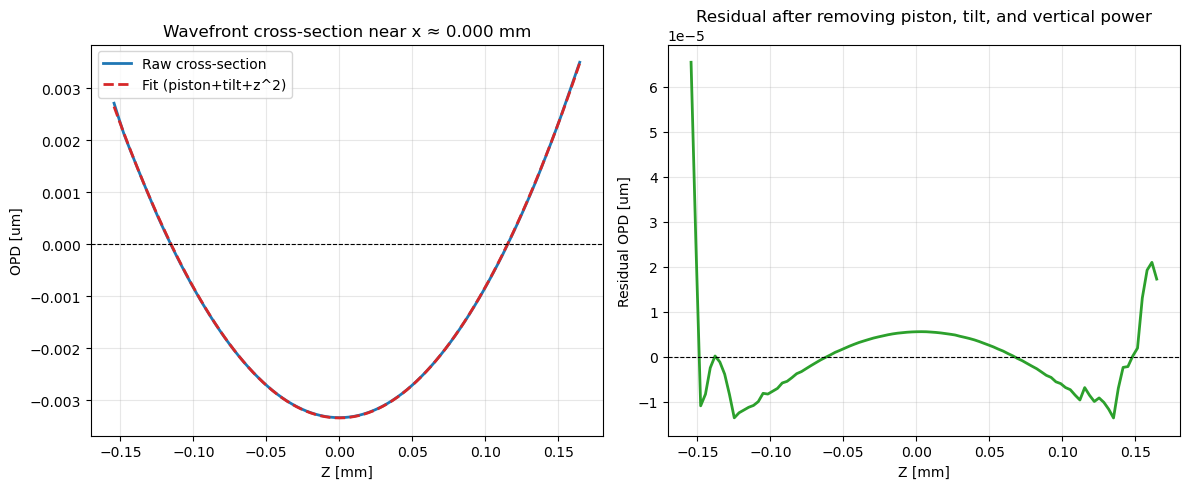

In [15]:
# Cross section near x=0 with piston, tilt, and vertical power removed
# Uses the existing X, Z, and wfe_um arrays from the notebook

x_idx = np.argmin(np.abs(X[0, :]))
x0 = X[0, x_idx]

z_cross = Z[:, x_idx]
wfe_cross = wfe_um[:, x_idx]

valid = np.isfinite(wfe_cross)
z_cross = z_cross[valid]
wfe_cross = wfe_cross[valid]

# Fit and remove piston + tilt + vertical power: a*z^2 + b*z + c
coeff_z = np.polyfit(z_cross, wfe_cross, 2)
p_z = np.poly1d(coeff_z)
wfe_cross_fit = p_z(z_cross)

wfe_cross_resid = wfe_cross - wfe_cross_fit
wfe_cross_resid = wfe_cross_resid - np.mean(wfe_cross_resid)

print(f"Cross-section fit coefficients [um]: a={coeff_z[0]:.6e}, b={coeff_z[1]:.6e}, c={coeff_z[2]:.6e}")
print(f"Residual RMS after removing piston + tilt + vertical power = {np.std(wfe_cross_resid):.6e} um")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(z_cross * 1e3, wfe_cross, color='tab:blue', lw=2, label='Raw cross-section')
ax1.plot(z_cross * 1e3, wfe_cross_fit, color='tab:red', lw=2, ls='--', label='Fit (piston+tilt+z^2)')
ax1.axhline(0, color='black', lw=0.8, ls='--')
ax1.set_title(f"Wavefront cross-section near x ≈ {x0 * 1e3:.3f} mm")
ax1.set_xlabel("Z [mm]")
ax1.set_ylabel("OPD [um]")
ax1.grid(True, alpha=0.3)
ax1.legend()

ax2.plot(z_cross * 1e3, wfe_cross_resid, color='tab:green', lw=2)
ax2.axhline(0, color='black', lw=0.8, ls='--')
ax2.set_title("Residual after removing piston, tilt, and vertical power")
ax2.set_xlabel("Z [mm]")
ax2.set_ylabel("Residual OPD [um]")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Looping 

In [43]:
bender = np.linspace(1200, 4200, 16)

/var/folders/hr/17npbd3151g552w6q43kqpr80000gn/T/ipykernel_7815/1915274162.py:12: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter(
/var/folders/hr/17npbd3151g552w6q43kqpr80000gn/T/ipykernel_7815/1915274162.py:27: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


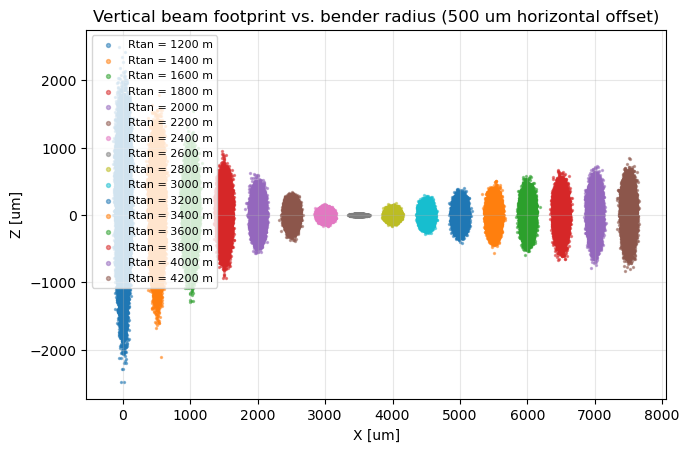

In [44]:
# Loop over bender settings and plot the beam footprint at the final screen,
# with each beam shifted horizontally by 500 um for clarity
fig, ax = plt.subplots(figsize=(7, 6))
offset_um = 500.0

for i, Rtan_m in enumerate(bender):
    beam = run_als531(Rtan_m=float(Rtan_m), drift_m=2)

    x_um = 1e6 * beam.get_column(1, nolost=1)
    z_um = 1e6 * beam.get_column(3, nolost=1)

    ax.scatter(
        x_um + i * offset_um,
        z_um,
        s=2,
        alpha=0.5,
        label=f"Rtan = {Rtan_m:.0f} m",
        c=plt.cm.tab10(i % 10),
    )

ax.set_xlabel("X [um]")
ax.set_ylabel("Z [um]")
ax.set_title("Vertical beam footprint vs. bender radius (500 um horizontal offset)")
ax.grid(True, alpha=0.3)
ax.set_aspect("equal")
ax.legend(markerscale=2, fontsize=8)
plt.tight_layout()
plt.show()

## calibrating WFS data with simulations (bender um-> ROC)